In [ ]:
import pandas as pd
import numpy as np
import matplotlib as mpl
df=pd.read_csv("https://raw.githubusercontent.com/bcaffo/ds4bme_intro/master/data/kirby127a_3_1_ax_283Labels_M2_corrected_stats.csv")
df.head(4) #give yuo the first 4 rows of csv if use .tail() do the opposite

,Unnamed: 0,rawid,roi,volume,min,max,mean,std,type,level
0,1,kirby127a_3_1_ax.img,Telencephalon_L,531111,0,374,128.3013,51.8593,1,1
1,2,kirby127a_3_1_ax.img,Telencephalon_R,543404,0,300,135.0683,53.6471,1,1
2,3,kirby127a_3_1_ax.img,Diencephalon_L,9683,15,295,193.5488,32.2733,1,1
3,4,kirby127a_3_1_ax.img,Diencephalon_R,9678,10,335,193.7051,32.7869,1,1


In [ ]:
df=df.drop(['Unnamed: 0', 'rawid', 'min', 'max', 'mean', 'std'], axis = 1) #drop out unwanted colums
df.head(4)


,roi,volume,type,level
0,Telencephalon_L,531111,1,1
1,Telencephalon_R,543404,1,1
2,Diencephalon_L,9683,1,1
3,Diencephalon_R,9678,1,1


In [ ]:
t1l1= df.loc[(df.type==1)&(df.level==1)] #extract those only with type,level=1
t1l1=t1l1.assign(icv=sum(t1l1.volume))
t1l1=t1l1.assign(tbv=sum(t1l1.volume[(t1l1.roi != 'CSF')]))
t1l1

,roi,volume,type,level,icv,tbv
0,Telencephalon_L,531111,1,1,1378295,1268519
1,Telencephalon_R,543404,1,1,1378295,1268519
2,Diencephalon_L,9683,1,1,1378295,1268519
3,Diencephalon_R,9678,1,1,1378295,1268519
4,Mesencephalon,10268,1,1,1378295,1268519
5,Metencephalon,159402,1,1,1378295,1268519
6,Myelencephalon,4973,1,1,1378295,1268519
7,CSF,109776,1,1,1378295,1268519


In [ ]:
t1l1=t1l1.assign(comp=lambda x: x.volume/x.tbv) #assing a new column of compostion ratio using lambda, x is the correpsonding records in comp
t1l1

,roi,volume,type,level,icv,tbv,comp
0,Telencephalon_L,531111,1,1,1378295,1268519,0.418686
1,Telencephalon_R,543404,1,1,1378295,1268519,0.428377
2,Diencephalon_L,9683,1,1,1378295,1268519,0.007633
3,Diencephalon_R,9678,1,1,1378295,1268519,0.007629
4,Mesencephalon,10268,1,1,1378295,1268519,0.008094
5,Metencephalon,159402,1,1,1378295,1268519,0.125660
6,Myelencephalon,4973,1,1,1378295,1268519,0.003920
7,CSF,109776,1,1,1378295,1268519,0.086539


<Axes: xlabel='roi'>

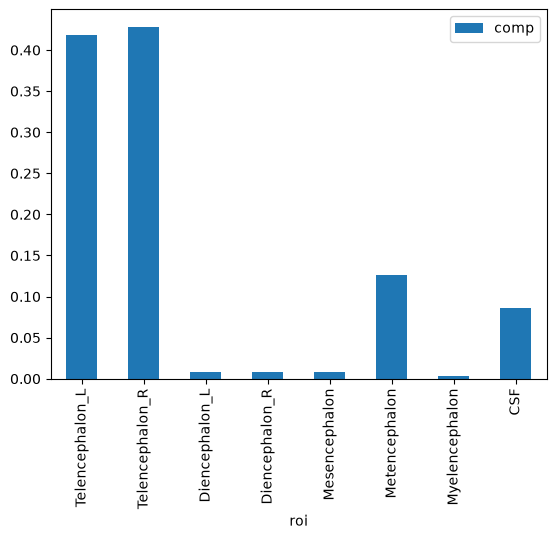

In [ ]:
t1l1.plot.bar(x='roi', y='comp') #simple plotting 

In [ ]:
#!pip install plotly==4.0.0
import plotly #interactive plotting tell you more info when hover your mouse over the bar
import plotly.express as px
myplot=px.bar(t1l1, x='roi', y='volume')
myplot.show()